# Notebook 1. Histopathology Image Classification for Lung, Colon, and Breast Tissue Classification Into Normal, Benign and Cancer Type (part 1)

**Project objective:** Develop and evaluate 3 deep learning models to classify histopathology images into their corresponding tissue categories. The project is intended for educational and research exploration, not clinical diagnosis.

In this project, a histopathology image dataset of **3,400 images across 9 classes**, covering lung, colon, and breast tissue, was used.

- **Lung:** 1,500 images divided into adenocarcinoma, squamous cell carcinoma, and benign tissue.
- **Colon:** 1,500 images divided into adenocarcinoma and benign tissue.
- **Breast:** 400 images divided into benign, carcinoma in situ, invasive carcinoma, and normal tissue.

The dataset is organized into separate folders based on tissue type and classification label.

# Dataset Exploration and Validation

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

In [3]:
from pathlib import Path
image_path = Path(r"C:\Users\Hp\Desktop\Cancer_Image_Classification")

print("Image path:", image_path)
print("Folder exists:", image_path.exists())

Image path: C:\Users\Hp\Desktop\Cancer_Image_Classification
Folder exists: True


In [4]:
# Display the folders inside the main image directory

for folder in image_path.iterdir():
    if folder.is_dir():
        print(folder.name)

Breast_Cancer_images
colon_tissue_images
lung_tissue_images


In [5]:
# Explore the classification folders

for tissue_folder in image_path.iterdir():
    if tissue_folder.is_dir():
        print(f"\n{tissue_folder.name}:")

        for class_folder in tissue_folder.iterdir():
            if class_folder.is_dir():
                print("   ", class_folder.name)


Breast_Cancer_images:
    breast_ben
    breast_insi
    breast_inv
    breast_n

colon_tissue_images:
    colon_aca
    colon_n

lung_tissue_images:
    lung_aca
    lung_n
    lung_scc


In [7]:
# Common image file formats
image_extensions = (".jpg", ".jpeg", ".png", ".tif", ".tiff", ".bmp")

In [8]:
# Create an empty list to store the results
image_counts = []

for tissue in image_path.iterdir():
    if tissue.is_dir():

        # Loop through class folders
        for class_folder in tissue.iterdir():
            if class_folder.is_dir():

                # Find image files
                images = [
                    file for file in class_folder.iterdir()
                    if file.suffix.lower() in image_extensions
                    and file.is_file()
                ]

                # Save the results
                image_counts.append([
                    tissue.name,
                    class_folder.name,
                    len(images)
                ])

In [9]:
# Convert image counts into a DataFrame
df_counts = pd.DataFrame(
    image_counts,
    columns=["Tissue", "Class", "Image Count"]
)

display(df_counts)

,Tissue,Class,Image Count
0,Breast_Cancer_images,breast_ben,100
1,Breast_Cancer_images,breast_insi,100
2,Breast_Cancer_images,breast_inv,100
3,Breast_Cancer_images,breast_n,100
4,colon_tissue_images,colon_aca,750
5,colon_tissue_images,colon_n,750
6,lung_tissue_images,lung_aca,500
7,lung_tissue_images,lung_n,500
8,lung_tissue_images,lung_scc,500


In [10]:
# Calculate total images
total_images = df_counts["Image Count"].sum()

print("Total number of images:", total_images)

Total number of images: 3400


In [11]:
# Count classification categories
total_classes = len(df_counts)

print("Total number of classes:", total_classes)

Total number of classes: 9


In [12]:
# Create an empty list
image_formats = []

# Visit each tissue and class folder
for tissue in image_path.iterdir():
    if tissue.is_dir():
        for class_folder in tissue.iterdir():
            if class_folder.is_dir():
                for file in class_folder.iterdir():
                    if file.is_file():
                        image_formats.append(file.suffix.lower())

In [13]:
# Count how many files use each extension
format_counts = pd.Series(image_formats).value_counts()

display(format_counts)

.jpeg    3000
.tif      400
Name: count, dtype: int64

In [15]:
# Empty list to store image dimensions
image_dimensions = []

In [16]:
for tissue in image_path.iterdir():
    if tissue.is_dir():

        for class_folder in tissue.iterdir():
            if class_folder.is_dir():

                for file in class_folder.iterdir():
                    if file.is_file() and file.suffix.lower() in image_extensions:

                        with Image.open(file) as img:
                            width, height = img.size

                        image_dimensions.append([
                            tissue.name,
                            class_folder.name,
                            width,
                            height
                        ])

In [17]:
df_dimensions = pd.DataFrame(
    image_dimensions,
    columns=["Tissue", "Class", "Width", "Height"]
)

display(df_dimensions.head())

,Tissue,Class,Width,Height
0,Breast_Cancer_images,breast_ben,2048,1536
1,Breast_Cancer_images,breast_ben,2048,1536
2,Breast_Cancer_images,breast_ben,2048,1536
3,Breast_Cancer_images,breast_ben,2048,1536
4,Breast_Cancer_images,breast_ben,2048,1536


In [18]:
df_dimensions.groupby("Tissue")[["Width", "Height"]].agg(
    ["min", "max"]
)

Width       Height      
                       min   max    min   max
Tissue                                       
Breast_Cancer_images  2048  2048   1536  1536
colon_tissue_images    768   768    768   768
lung_tissue_images     768   768    768   768

**Lung and Colon**

Both datasets contain images measuring 768 × 768 pixels.
- They are square images.
- Their dimensions are consistent.
- We can use similar preprocessing approaches for both datasets.

**Breast**

The breast images measure 2048 × 1536 pixels.
- They are rectangular images.
- They contain more pixels than the lung and colon images.
- Reducing their resolution can remove important microscopic details.

In [19]:
# Create an empty list
image_modes = []

# Check one image from each tissue
for tissue in image_path.iterdir():
    if tissue.is_dir():
        class_folder = next(
            folder for folder in tissue.iterdir() if folder.is_dir()
        )

        image_file = next(
            file for file in class_folder.iterdir()
            if file.is_file() and file.suffix.lower() in image_extensions
        )

        with Image.open(image_file) as img:
            image_modes.append([tissue.name, img.mode])

In [21]:
df_modes = pd.DataFrame(
    image_modes,
    columns=["Tissue", "Color Mode"]
)

display(df_modes)

,Tissue,Color Mode
0,Breast_Cancer_images,RGB
1,colon_tissue_images,RGB
2,lung_tissue_images,RGB


### The sample images from all three tissue types use RGB color mode.

In [22]:
# Store any images that cannot be read
invalid_images = []

for tissue in image_path.iterdir():
    if tissue.is_dir():
        for class_folder in tissue.iterdir():
            if class_folder.is_dir():
                for file in class_folder.iterdir():
                    if file.is_file() and file.suffix.lower() in image_extensions:
                        try:
                            with Image.open(file) as img:
                                img.load()
                        except Exception as error:
                            invalid_images.append([str(file), str(error)])

In [23]:
print("Invalid images:", len(invalid_images))

if invalid_images:
    display(pd.DataFrame(invalid_images, columns=["File", "Error"]))
else:
    print("All images loaded successfully!")

Invalid images: 0
All images loaded successfully!


In [24]:
# Select the breast benign folder
breast_folder = image_path / "Breast_Cancer_images" / "breast_ben"

# Find the first TIFF image
image_file = next(breast_folder.glob("*.tif"))

# Open the image
img = Image.open(image_file)

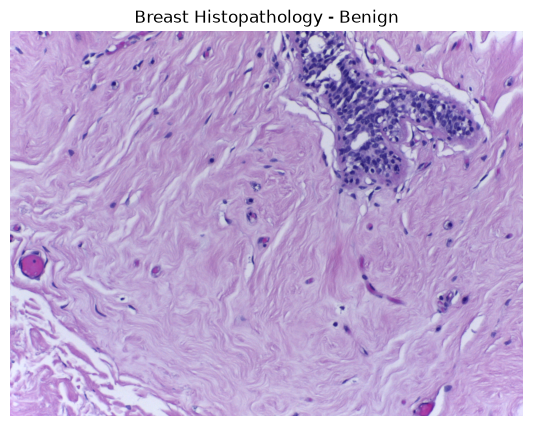

In [25]:
plt.figure(figsize=(8, 5))

plt.imshow(img)
plt.title("Breast Histopathology - Benign")
plt.axis("off")

plt.show()

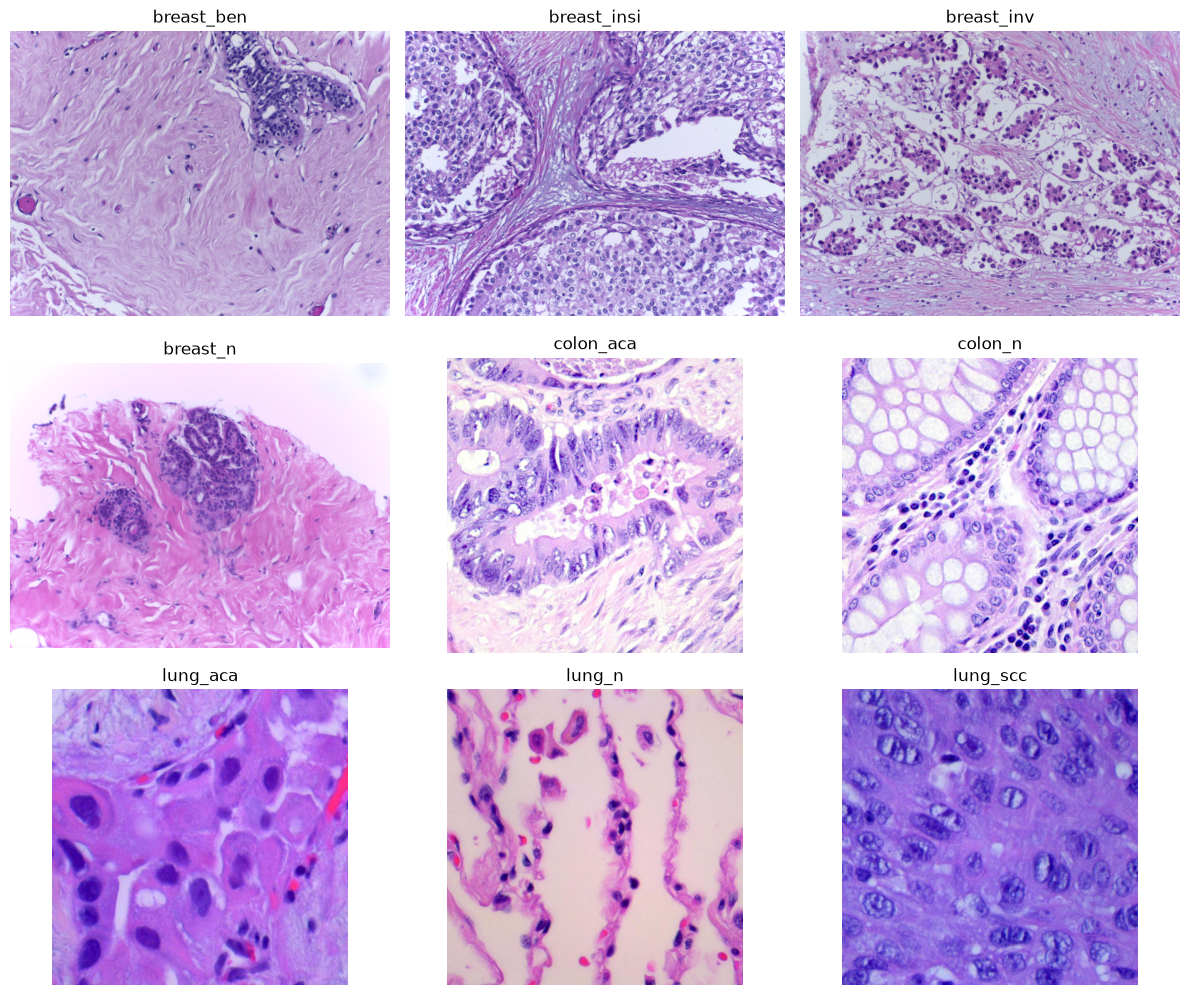

In [33]:
# Create a figure containing 9 plots
fig, axes = plt.subplots(3, 3, figsize=(12, 10))

# Display one image per class
for ax, (class_name, file) in zip(axes.flat, sample_images):

    with Image.open(file) as img:
        ax.imshow(img)

    ax.set_title(class_name)
    ax.axis("off")

# Adjust spacing between images
fig.tight_layout()

# Display the figure
plt.show()

In [34]:
import hashlib

In [35]:
# Collect all image files
all_images = []

for tissue in image_path.iterdir():
    if tissue.is_dir():
        for class_folder in tissue.iterdir():
            if class_folder.is_dir():
                for file in class_folder.iterdir():
                    if file.is_file() and file.suffix.lower() in image_extensions:
                        all_images.append(file)

print("Images collected:", len(all_images))

Images collected: 3400


In [36]:
# Dictionary to store image fingerprints
hashes = {}

for file in all_images:
    with open(file, "rb") as f:
        file_hash = hashlib.file_digest(f, "sha256").hexdigest()

    if file_hash not in hashes:
        hashes[file_hash] = []

    hashes[file_hash].append(file)

print("Fingerprint generation completed!")

Fingerprint generation completed!


### Detect Exact Duplicate Images

In [37]:
# Create an empty list for duplicate groups
duplicate_groups = []

# Check the fingerprints
for files in hashes.values():
    if len(files) > 1:
        duplicate_groups.append(files)

# Display the results
print("Duplicate groups:", len(duplicate_groups))

Duplicate groups: 25


In [39]:
for i, group in enumerate(duplicate_groups, start=1):
    print(f"\nDuplicate Group {i}:")

    for file in group:
        print(file.parent.name, ":", file.name)


Duplicate Group 1:
colon_aca : colonca1083.jpeg
colon_aca : colonca380.jpeg

Duplicate Group 2:
colon_aca : colonca1736.jpeg
colon_aca : colonca4151.jpeg

Duplicate Group 3:
colon_aca : colonca194.jpeg
colon_aca : colonca3042.jpeg

Duplicate Group 4:
colon_aca : colonca2018.jpeg
colon_aca : colonca597.jpeg

Duplicate Group 5:
colon_aca : colonca2281.jpeg
colon_aca : colonca4469.jpeg

Duplicate Group 6:
colon_aca : colonca2744.jpeg
colon_aca : colonca671.jpeg

Duplicate Group 7:
colon_aca : colonca3547.jpeg
colon_aca : colonca4952.jpeg

Duplicate Group 8:
colon_aca : colonca4423.jpeg
colon_aca : colonca775.jpeg

Duplicate Group 9:
colon_n : colonn116.jpeg
colon_n : colonn1842.jpeg

Duplicate Group 10:
colon_n : colonn1672.jpeg
colon_n : colonn2894.jpeg

Duplicate Group 11:
colon_n : colonn3371.jpeg
colon_n : colonn4238.jpeg

Duplicate Group 12:
colon_n : colonn3967.jpeg
colon_n : colonn451.jpeg

Duplicate Group 13:
lung_aca : lungaca197.jpeg
lung_aca : lungaca67.jpeg

Duplicate Group 1

#### Remove Duplicate Images

In [40]:
# Create a list of duplicate files to remove
files_to_remove = []

for group in duplicate_groups:
    files_to_remove.extend(group[1:])

print("Files selected for removal:", len(files_to_remove))

Files selected for removal: 25


In [41]:
# Remove duplicate files
for file in files_to_remove:
    file.unlink()

print("Duplicate files removed:", len(files_to_remove))

Duplicate files removed: 25


### Dataset After Cleaning

In [42]:
df_clean = pd.DataFrame(
    [
        [tissue.name, folder.name,
         len([f for f in folder.iterdir()
              if f.is_file() and f.suffix.lower() in image_extensions])]

        for tissue in image_path.iterdir() if tissue.is_dir()
        for folder in tissue.iterdir() if folder.is_dir()
    ],
    columns=["Tissue", "Class", "Image Count"]
)

display(df_clean)
print("Total images:", df_clean["Image Count"].sum())

,Tissue,Class,Image Count
0,Breast_Cancer_images,breast_ben,100
1,Breast_Cancer_images,breast_insi,100
2,Breast_Cancer_images,breast_inv,100
3,Breast_Cancer_images,breast_n,100
4,colon_tissue_images,colon_aca,742
5,colon_tissue_images,colon_n,746
6,lung_tissue_images,lung_aca,496
7,lung_tissue_images,lung_n,495
8,lung_tissue_images,lung_scc,496


Total images: 3375


# 3. Models 

## Model 1: Lung Histopathology Classification

This section focuses on developing and evaluating a deep learning model to classify lung histopathology images into three categories:

- **Adenocarcinoma (`lung_aca`):** 496 images
- **Benign tissue (`lung_n`):** 495 images
- **Squamous Cell Carcinoma (`lung_scc`):** 496 images

The dataset contains **1,487 JPEG images** with dimensions of **768 × 768 pixels**.

The objective is to preprocess the images, train a CNN model, evaluate its classification performance, and explore improvements using transfer learning.

In [43]:
# Define the lung dataset path
lung_path = image_path / "lung_tissue_images"

# Check the folder
print("Lung dataset:", lung_path)
print("Folder exists:", lung_path.exists())

Lung dataset: C:\Users\Hp\Desktop\Cancer_Image_Classification\lung_tissue_images
Folder exists: True


In [44]:
# Create an empty list
lung_data = []

# Loop through the lung classification folders
for class_folder in lung_path.iterdir():
    if class_folder.is_dir():

        for file in class_folder.iterdir():
            if file.is_file() and file.suffix.lower() in image_extensions:

                lung_data.append([str(file), class_folder.name])

In [45]:
df_lung = pd.DataFrame(
    lung_data,
    columns=["Image Path", "Label"]
)

display(df_lung.head())

print("Total lung images:", len(df_lung))

,Image Path,Label
0,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,lung_aca
1,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,lung_aca
2,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,lung_aca
3,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,lung_aca
4,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,lung_aca


Total lung images: 1487


In [46]:
# Count images for each lung class
df_lung["Label"].value_counts()

Label
lung_aca    496
lung_scc    496
lung_n      495
Name: count, dtype: int64

In [47]:
# Display the first 10 lung image filenames
for path in df_lung["Image Path"].head(10):
    print(Path(path).name)

lungaca1.jpeg
lungaca10.jpeg
lungaca100.jpeg
lungaca101.jpeg
lungaca102.jpeg
lungaca103.jpeg
lungaca104.jpeg
lungaca105.jpeg
lungaca106.jpeg
lungaca107.jpeg


In [48]:
# Select lung adenocarcinoma images
aca_images = df_lung[
    df_lung["Label"] == "lung_aca"
]["Image Path"].head(6)

print("Selected images:", len(aca_images))

Selected images: 6


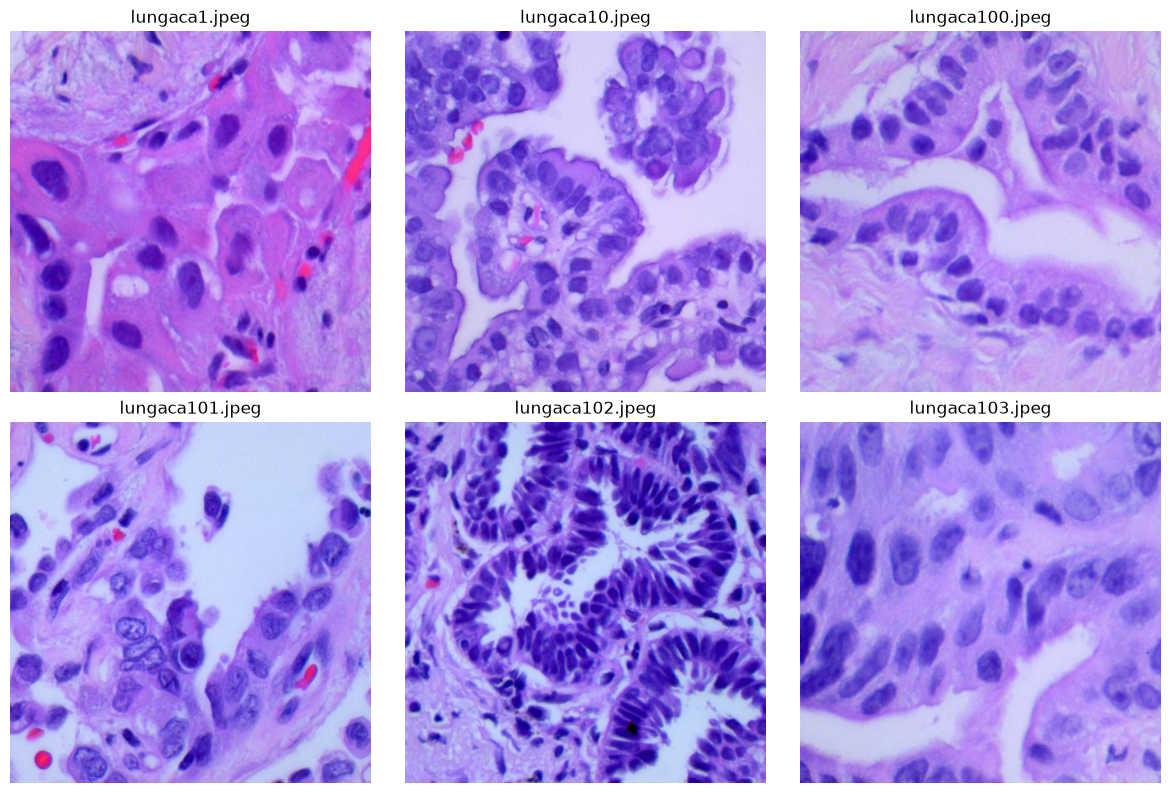

In [49]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

for ax, file in zip(axes.flat, aca_images):
    with Image.open(file) as img:
        ax.imshow(img)

    ax.set_title(Path(file).name)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [51]:
import imagehash

In [52]:
from sklearn.model_selection import train_test_split

In [53]:
df_train, df_temp = train_test_split(df_lung, test_size=0.30, random_state=42, stratify=df_lung["Label"])

In [55]:
df_val, df_test = train_test_split(df_temp, test_size=0.50, random_state=42, stratify=df_temp["Label"])

In [56]:
print("Training images:", len(df_train))
print("Validation images:", len(df_val))
print("Testing images:", len(df_test))

print("Total images:",
      len(df_train) + len(df_val) + len(df_test))

Training images: 1040
Validation images: 223
Testing images: 224
Total images: 1487


In [57]:
# Count classes in each dataset
train_counts = df_train["Label"].value_counts()
val_counts = df_val["Label"].value_counts()
test_counts = df_test["Label"].value_counts()

In [58]:
# Compare class distribution
df_split_counts = pd.DataFrame({
    "Training": train_counts,
    "Validation": val_counts,
    "Testing": test_counts
})

display(df_split_counts)

,Training,Validation,Testing
Label,,,
lung_aca,347,75,74
lung_n,346,74,75
lung_scc,347,74,75


In [59]:
# Create a folder for dataset split information
split_path = image_path / "splits"

split_path.mkdir(exist_ok=True)

print("Split folder:", split_path)

Split folder: C:\Users\Hp\Desktop\Cancer_Image_Classification\splits


In [60]:
df_train.to_csv(split_path / "lung_train.csv", index=False)

df_val.to_csv(split_path / "lung_val.csv", index=False)

df_test.to_csv(split_path / "lung_test.csv", index=False)

print("Lung dataset splits saved successfully!")

Lung dataset splits saved successfully!


In [61]:
# Define the input size for CNN
IMG_SIZE = (224, 224)

print("CNN input size:", IMG_SIZE)

CNN input size: (224, 224)


In [62]:
# Select the first training image
sample_path = df_train["Image Path"].iloc[0]

# Open and prepare the image
with Image.open(sample_path) as img:
    original_img = img.convert("RGB").copy()
    resized_img = original_img.resize(IMG_SIZE)

print("Original size:", original_img.size)
print("Resized size:", resized_img.size)

Original size: (768, 768)
Resized size: (224, 224)


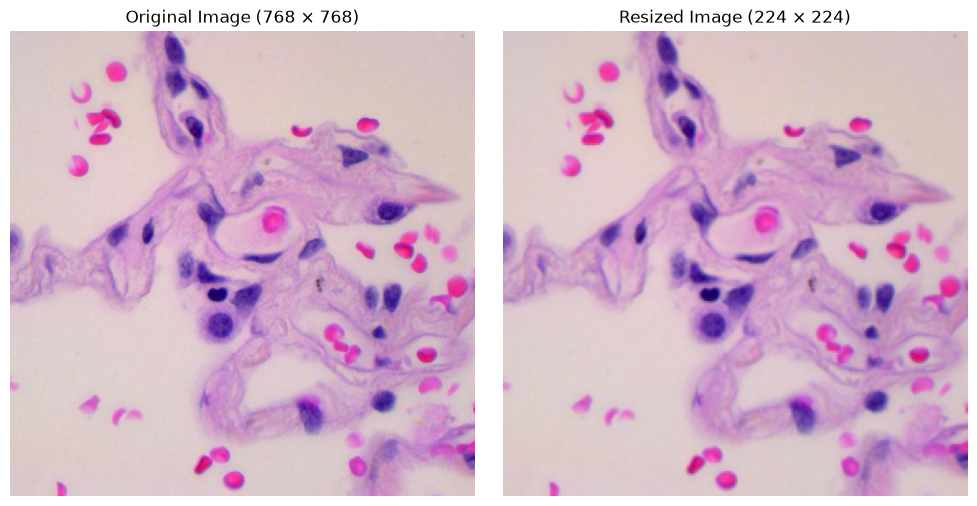

In [63]:
# Create two plots side by side
fig, axes = plt.subplots(1, 2, figsize=(10, 5))

# Display original image
axes[0].imshow(original_img)
axes[0].set_title("Original Image (768 × 768)")
axes[0].axis("off")

# Display resized image
axes[1].imshow(resized_img)
axes[1].set_title("Resized Image (224 × 224)")
axes[1].axis("off")

plt.tight_layout()
plt.show()


In [66]:
# Normalize pixel values between 0 and 1
img_normalized = img_array.astype("float32") / 255.0

print("Minimum normalized value:", img_normalized.min())
print("Maximum normalized value:", img_normalized.max())

Minimum normalized value: 0.0
Maximum normalized value: 1.0


In [69]:
import tensorflow as tf
from tensorflow.keras import layers, models

print("TensorFlow version:", tf.__version__)

TensorFlow version: 2.21.0


In [70]:
# Create our baseline CNN model
lung_model = models.Sequential([
    
    # Input layer
    layers.Input(shape=(224, 224, 3)),

    # Normalize pixel values from 0-255 to 0-1
    layers.Rescaling(1./255),

    # First convolutional block
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Second convolutional block
    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Third convolutional block
    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Convert feature maps into a feature vector
    layers.GlobalAveragePooling2D(),

    # Classification layer
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    # Output layer: 3 lung classes
    layers.Dense(3, activation="softmax")
])


In [71]:
lung_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print("Lung CNN model compiled successfully!")


Lung CNN model compiled successfully!


In [72]:
lung_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 3)              │           195 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,699 (397.26 KB)

 Trainable params: 101,699 (397.26 KB)

 Non-trainable params: 0 (0.00 B)

In [73]:
# Define batch size
BATCH_SIZE = 32

# Define the classification labels
class_names = ["lung_aca", "lung_n", "lung_scc"]

# Convert class names into numerical labels
label_map = {
    "lung_aca": 0,
    "lung_n": 1,
    "lung_scc": 2
}

print(label_map)

{'lung_aca': 0, 'lung_n': 1, 'lung_scc': 2}


In [74]:
def load_image(path, label):
    # Read image file
    image = tf.io.read_file(path)

    # Decode JPEG image into RGB
    image = tf.io.decode_jpeg(image, channels=3)

    # Resize image
    image = tf.image.resize(image, (224, 224))

    return image, label

In [75]:
def create_dataset(df, training=False):
    # Get image paths and numerical labels
    paths = df["Image Path"].values
    labels = df["Label"].map(label_map).values

    # Create TensorFlow dataset
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    # Shuffle training images only
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42
        )

    # Load and resize images
    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Group images into batches
    dataset = dataset.batch(BATCH_SIZE)

    # Optimize loading performance
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [76]:
# Create TensorFlow datasets
train_ds = create_dataset(df_train, training=True)

val_ds = create_dataset(df_val)

test_ds = create_dataset(df_test)

print("TensorFlow datasets created successfully!")

TensorFlow datasets created successfully!


In [77]:
# Inspect the first training batch
for images, labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:", images.numpy().min(), images.numpy().max())

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 255.0


In [78]:
# Train the baseline CNN
history = lung_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10
)


Epoch 1/10


C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


33/33 ━━━━━━━━━━━━━━━━━━━━ 39s 1s/step - accuracy: 0.6058 - loss: 0.8430 - val_accuracy: 0.7265 - val_loss: 0.5165
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 32s 963ms/step - accuracy: 0.7490 - loss: 0.5228 - val_accuracy: 0.7982 - val_loss: 0.4341
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.7942 - loss: 0.4546 - val_accuracy: 0.7758 - val_loss: 0.4507
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.8077 - loss: 0.4294 - val_accuracy: 0.8296 - val_loss: 0.3651
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 38s 1s/step - accuracy: 0.8298 - loss: 0.4121 - val_accuracy: 0.8565 - val_loss: 0.3505
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 33s 977ms/step - accuracy: 0.8212 - loss: 0.4064 - val_accuracy: 0.8565 - val_loss: 0.3320
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 36s 1s/step - accuracy: 0.8231 - loss: 0.4223 - val_accuracy: 0.8565 - val_loss: 0.3186
Epoch 8/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.8519 - loss: 0.3795 - val_accuracy: 0.8655 - val_loss: 0.33

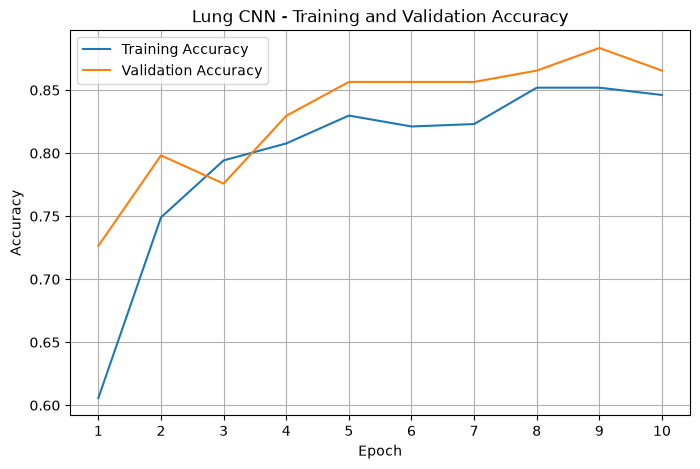

In [80]:
epochs = range(1, len(history.history["accuracy"]) + 1)

plt.figure(figsize=(8, 5))

plt.plot(epochs, history.history["accuracy"],
         label="Training Accuracy")

plt.plot(epochs, history.history["val_accuracy"],
         label="Validation Accuracy")

plt.title("Lung CNN - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(epochs)
plt.legend()
plt.grid(True)

plt.show()

### Evaluate the Lung CNN on Test Data

In [82]:
# Evaluate the CNN on the test dataset
test_loss, test_accuracy = lung_model.evaluate(test_ds)

print(f"Test Accuracy: {test_accuracy:.2%}")
print(f"Test Loss: {test_loss:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 240ms/step - accuracy: 0.8616 - loss: 0.3321
Test Accuracy: 86.16%
Test Loss: 0.3321


Lung CNN Test Evaluation
BASELINE CNN — TEST RESULTS
Test accuracy
86.16%

Test loss
0.3321

Test images
224

Classification categories
3

In [83]:
from sklearn.metrics import classification_report

In [84]:
# Generate predictions for the test dataset
y_prob = lung_model.predict(test_ds)

# Convert predicted probabilities to class labels
y_pred = np.argmax(y_prob, axis=1)

# Collect actual class labels
y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

print("Predictions:", len(y_pred))
print("Actual labels:", len(y_true))


7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 255ms/step
Predictions: 224
Actual labels: 224


In [85]:

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4
))


              precision    recall  f1-score   support

    lung_aca     0.7945    0.7838    0.7891        74
      lung_n     0.9722    0.9333    0.9524        75
    lung_scc     0.8228    0.8667    0.8442        75

    accuracy                         0.8616       224
   macro avg     0.8632    0.8613    0.8619       224
weighted avg     0.8635    0.8616    0.8622       224



In [86]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

print(cm)

[[58  2 14]
 [ 5 70  0]
 [10  0 65]]


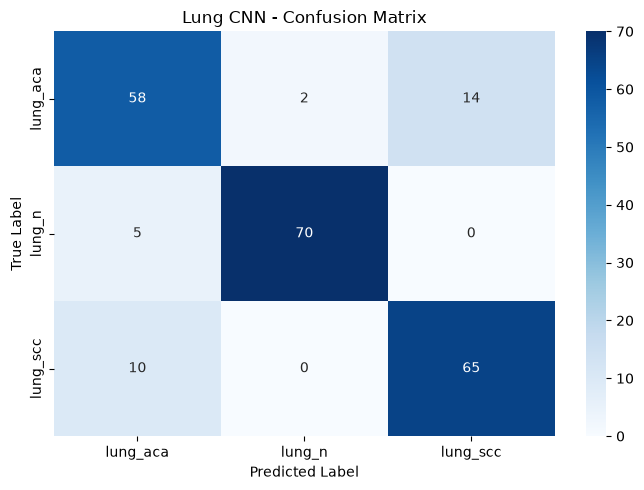

In [87]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Lung CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()


In [88]:
# Create a folder for trained models
models_path = image_path / "models"
models_path.mkdir(exist_ok=True)

# Save the trained lung CNN
lung_model.save(models_path / "lung_cnn_baseline.keras")

print("Lung model saved successfully!")

Lung model saved successfully!


## Model 2: Colon Histology Classification

In [89]:
# Define the colon dataset folder
colon_path = image_path / "colon_tissue_images"

# Check the folder
print("Colon dataset:", colon_path)
print("Folder exists:", colon_path.exists())

Colon dataset: C:\Users\Hp\Desktop\Cancer_Image_Classification\colon_tissue_images
Folder exists: True


In [91]:
# Create an empty list
colon_data = []

# Loop through colon class folders
for class_folder in colon_path.iterdir():
    if class_folder.is_dir():

        for file in class_folder.iterdir():
            if file.is_file() and file.suffix.lower() in image_extensions:

                colon_data.append([
                    str(file),
                    class_folder.name
                ])

In [92]:
# Create the colon DataFrame
df_colon = pd.DataFrame(
    colon_data,
    columns=["Image Path", "Label"]
)

display(df_colon.head())

print("Total colon images:", len(df_colon))

,Image Path,Label
0,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,colon_aca
1,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,colon_aca
2,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,colon_aca
3,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,colon_aca
4,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,colon_aca


Total colon images: 1488


In [93]:
# Count images per class
df_colon["Label"].value_counts()

Label
colon_n      746
colon_aca    742
Name: count, dtype: int64

In [94]:
# Split into 70% training and 30% temporary data
df_colon_train, df_colon_temp = train_test_split(
    df_colon,
    test_size=0.30,
    random_state=42,
    stratify=df_colon["Label"]
)

In [95]:
# Split into 70% training and 30% temporary data
df_colon_train, df_colon_temp = train_test_split(
    df_colon,
    test_size=0.30,
    random_state=42,
    stratify=df_colon["Label"]
)

In [96]:
# Divide the remaining 30% equally
df_colon_val, df_colon_test = train_test_split(
    df_colon_temp,
    test_size=0.50,
    random_state=42,
    stratify=df_colon_temp["Label"]
)

In [97]:
print("Training images:", len(df_colon_train))
print("Validation images:", len(df_colon_val))
print("Testing images:", len(df_colon_test))

print("Total images:",
      len(df_colon_train) + len(df_colon_val) + len(df_colon_test))

Training images: 1041
Validation images: 223
Testing images: 224
Total images: 1488


In [98]:
# Save colon training, validation, and testing splits

df_colon_train.to_csv(split_path / "colon_train.csv", index=False)

df_colon_val.to_csv(split_path / "colon_val.csv", index=False)

df_colon_test.to_csv(split_path / "colon_test.csv", index=False)

print("Colon dataset splits saved successfully!")

Colon dataset splits saved successfully!


In [99]:
# Check whether all three CSV files exist

for name in ["colon_train.csv", "colon_val.csv", "colon_test.csv"]:
    print(name, (split_path / name).exists())

colon_train.csv True
colon_val.csv True
colon_test.csv True


In [100]:
# Create the colon CNN model
colon_model = models.Sequential([

    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),

    # Convolutional blocks
    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    # Classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    # Binary classification output
    layers.Dense(1, activation="sigmoid")
])

In [101]:
colon_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

print("Colon CNN compiled successfully!")

Colon CNN compiled successfully!


In [102]:
colon_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_1 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,569 (396.75 KB)

 Trainable params: 101,569 (396.75 KB)

 Non-trainable params: 0 (0.00 B)

In [103]:
# Define the two colon classes
colon_class_names = ["colon_aca", "colon_n"]

# Assign numerical labels
colon_label_map = {
    "colon_aca": 0,
    "colon_n": 1
}

print(colon_label_map)

{'colon_aca': 0, 'colon_n': 1}


In [104]:
def create_colon_dataset(df, training=False):

    # Get image paths and numerical labels
    paths = df["Image Path"].values
    labels = df["Label"].map(colon_label_map).values.astype("float32")

    # Create TensorFlow dataset
    dataset = tf.data.Dataset.from_tensor_slices((paths, labels))

    # Shuffle training data only
    if training:
        dataset = dataset.shuffle(
            buffer_size=len(df),
            seed=42
        )

    # Load and resize images
    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    # Create batches
    dataset = dataset.batch(32)

    # Improve data loading performance
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [105]:
colon_train_ds = create_colon_dataset(
    df_colon_train, training=True
)

colon_val_ds = create_colon_dataset(df_colon_val)

colon_test_ds = create_colon_dataset(df_colon_test)

print("Colon TensorFlow datasets created successfully!")

Colon TensorFlow datasets created successfully!


In [106]:
for images, labels in colon_train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", labels.shape)
    print("Pixel range:", images.numpy().min(), images.numpy().max())
    print("Labels:", labels.numpy()[:10])

Image batch shape: (32, 224, 224, 3)
Label batch shape: (32,)
Pixel range: 0.0 255.0
Labels: [0. 1. 0. 0. 0. 0. 0. 1. 1. 1.]


In [107]:
# Train the colon CNN
colon_history = colon_model.fit(
    colon_train_ds,
    validation_data=colon_val_ds,
    epochs=10
)

Epoch 1/10


C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


33/33 ━━━━━━━━━━━━━━━━━━━━ 40s 1s/step - accuracy: 0.5005 - loss: 0.6974 - val_accuracy: 0.5022 - val_loss: 0.6928
Epoch 2/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 33s 996ms/step - accuracy: 0.5235 - loss: 0.6929 - val_accuracy: 0.5561 - val_loss: 0.6908
Epoch 3/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 33s 985ms/step - accuracy: 0.5447 - loss: 0.6890 - val_accuracy: 0.4978 - val_loss: 0.6786
Epoch 4/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 32s 959ms/step - accuracy: 0.5735 - loss: 0.6794 - val_accuracy: 0.4978 - val_loss: 0.6968
Epoch 5/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.6811 - loss: 0.6203 - val_accuracy: 0.7354 - val_loss: 0.5268
Epoch 6/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.7695 - loss: 0.4792 - val_accuracy: 0.7848 - val_loss: 0.4357
Epoch 7/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.7723 - loss: 0.4769 - val_accuracy: 0.7534 - val_loss: 0.4908
Epoch 8/10
33/33 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.8079 - loss: 0.4243 - val_accuracy: 0.8251 - val_loss: 0

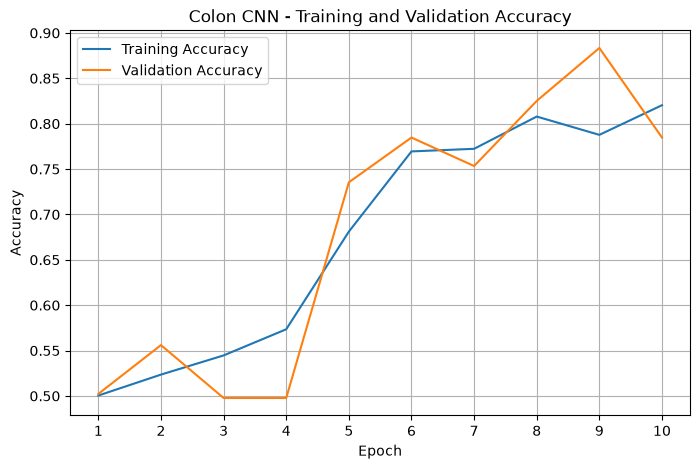

In [108]:
# Define the epochs
colon_epochs = range(1, len(colon_history.history["accuracy"]) + 1)

# Plot accuracy
plt.figure(figsize=(8, 5))

plt.plot(colon_epochs, colon_history.history["accuracy"],
         label="Training Accuracy")

plt.plot(colon_epochs, colon_history.history["val_accuracy"],
         label="Validation Accuracy")

plt.title("Colon CNN - Training and Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.xticks(colon_epochs)
plt.legend()
plt.grid(True)

plt.show()

In [109]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

checkpoint = ModelCheckpoint(
    "colon_cnn_best.keras",
    monitor="val_loss",
    save_best_only=True
)

In [110]:
colon_history = colon_model.fit(
    colon_train_ds,
    validation_data=colon_val_ds,
    epochs=20,
    callbacks=[early_stopping, checkpoint]
)

Epoch 1/20


C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


33/33 ━━━━━━━━━━━━━━━━━━━━ 41s 1s/step - accuracy: 0.8386 - loss: 0.3747 - val_accuracy: 0.9148 - val_loss: 0.2995
Epoch 2/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 37s 1s/step - accuracy: 0.8396 - loss: 0.3779 - val_accuracy: 0.8430 - val_loss: 0.3611
Epoch 3/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 35s 1s/step - accuracy: 0.8425 - loss: 0.3593 - val_accuracy: 0.9327 - val_loss: 0.2574
Epoch 4/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 32s 966ms/step - accuracy: 0.8549 - loss: 0.3426 - val_accuracy: 0.9148 - val_loss: 0.2714
Epoch 5/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 33s 1s/step - accuracy: 0.8377 - loss: 0.3594 - val_accuracy: 0.9283 - val_loss: 0.2300
Epoch 6/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 33s 998ms/step - accuracy: 0.8549 - loss: 0.3411 - val_accuracy: 0.9148 - val_loss: 0.2719
Epoch 7/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.8751 - loss: 0.3072 - val_accuracy: 0.9193 - val_loss: 0.2668
Epoch 8/20
33/33 ━━━━━━━━━━━━━━━━━━━━ 34s 1s/step - accuracy: 0.8501 - loss: 0.3522 - val_accuracy: 0.9013 - val_loss: 0.33

In [111]:
val_loss, val_accuracy = colon_model.evaluate(colon_val_ds)

print(f"Validation Accuracy: {val_accuracy:.2%}")
print(f"Validation Loss: {val_loss:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 288ms/step - accuracy: 0.9283 - loss: 0.2300
Validation Accuracy: 92.83%
Validation Loss: 0.2300


In [112]:
# Evaluate colon CNN on the test dataset
colon_test_loss, colon_test_accuracy = colon_model.evaluate(
    colon_test_ds
)

print(f"Test Accuracy: {colon_test_accuracy:.2%}")
print(f"Test Loss: {colon_test_loss:.4f}")

7/7 ━━━━━━━━━━━━━━━━━━━━ 2s 229ms/step - accuracy: 0.8661 - loss: 0.3091
Test Accuracy: 86.61%
Test Loss: 0.3091


In [113]:
# Predict colon test images
colon_prob = colon_model.predict(colon_test_ds)

# Convert probabilities into class labels (0 or 1)
colon_pred = (colon_prob.flatten() >= 0.5).astype(int)

# Get the actual labels
colon_true = np.concatenate([
    labels.numpy() for images, labels in colon_test_ds
]).astype(int)

print("Predictions:", len(colon_pred))
print("Actual labels:", len(colon_true))

7/7 ━━━━━━━━━━━━━━━━━━━━ 3s 303ms/step
Predictions: 224
Actual labels: 224


In [114]:
from sklearn.metrics import confusion_matrix

colon_cm = confusion_matrix(
    colon_true,
    colon_pred,
    labels=[0, 1]
)

print(colon_cm)

[[ 92  20]
 [ 10 102]]


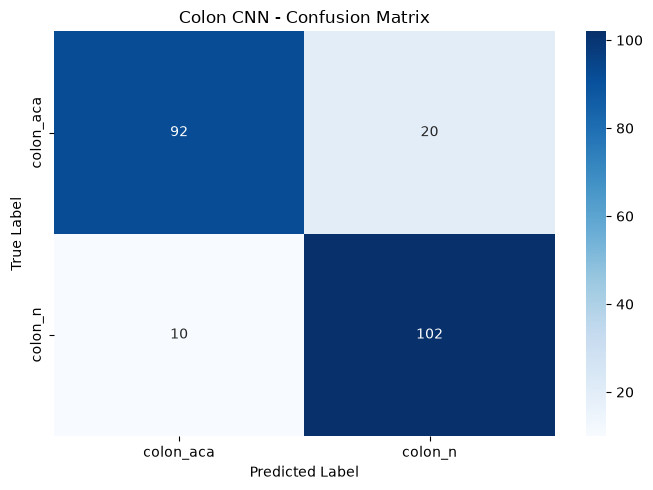

In [115]:
plt.figure(figsize=(7, 5))

sns.heatmap(
    colon_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=colon_class_names,
    yticklabels=colon_class_names
)

plt.title("Colon CNN - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

In [116]:
# Cancer (colon_aca = 0) is our positive class

TP = colon_cm[0, 0]
FN = colon_cm[0, 1]
FP = colon_cm[1, 0]
TN = colon_cm[1, 1]

print("True Positives:", TP)
print("False Negatives:", FN)
print("False Positives:", FP)
print("True Negatives:", TN)

True Positives: 92
False Negatives: 20
False Positives: 10
True Negatives: 102


In [117]:
# Calculate false negative and false positive rates

fnr = FN / (FN + TP)
fpr = FP / (FP + TN)

sensitivity = TP / (TP + FN)
specificity = TN / (TN + FP)

print(f"False Negative Rate: {fnr:.2%}")
print(f"False Positive Rate: {fpr:.2%}")
print(f"Sensitivity: {sensitivity:.2%}")
print(f"Specificity: {specificity:.2%}")

False Negative Rate: 17.86%
False Positive Rate: 8.93%
Sensitivity: 82.14%
Specificity: 91.07%


In [119]:
print(classification_report(
    colon_true,
    colon_pred,
    target_names=colon_class_names,
    digits=4
))

              precision    recall  f1-score   support

   colon_aca     0.9020    0.8214    0.8598       112
     colon_n     0.8361    0.9107    0.8718       112

    accuracy                         0.8661       224
   macro avg     0.8690    0.8661    0.8658       224
weighted avg     0.8690    0.8661    0.8658       224



Save the Colon CNN

In [120]:
# Save the trained colon CNN
colon_model.save(models_path / "colon_cnn_baseline.keras")

print("Colon CNN saved successfully!")

Colon CNN saved successfully!


### Model 3: Breast Cancer Histopathology Classification

This section focuses on developing and evaluating a CNN model for breast histopathology image classification.

The dataset contains **400 TIFF images** (2048 × 1536 pixels) distributed equally across four categories:

- **Benign (`breast_ben`):** 100 images
- **Carcinoma in Situ (`breast_insi`):** 100 images
- **Invasive Carcinoma (`breast_inv`):** 100 images
- **Normal tissue (`breast_n`):** 100 images

In [121]:
# Define breast dataset location
breast_path = image_path / "Breast_Cancer_images"

print("Breast dataset:", breast_path)
print("Folder exists:", breast_path.exists())

Breast dataset: C:\Users\Hp\Desktop\Cancer_Image_Classification\Breast_Cancer_images
Folder exists: True


In [122]:
# Create an empty list
breast_data = []

# Loop through the breast classification folders
for class_folder in breast_path.iterdir():
    if class_folder.is_dir():

        for file in class_folder.iterdir():
            if file.is_file() and file.suffix.lower() in image_extensions:

                breast_data.append([
                    str(file),
                    class_folder.name
                ])

In [123]:
# Create the breast DataFrame
df_breast = pd.DataFrame(
    breast_data,
    columns=["Image Path", "Label"]
)

display(df_breast.head())

print("Total breast images:", len(df_breast))

,Image Path,Label
0,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,breast_ben
1,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,breast_ben
2,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,breast_ben
3,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,breast_ben
4,C:\Users\Hp\Desktop\Cancer_Image_Classificatio...,breast_ben


Total breast images: 400


In [124]:
# Count images in each breast class
df_breast["Label"].value_counts()

Label
breast_ben     100
breast_insi    100
breast_inv     100
breast_n       100
Name: count, dtype: int64

In [125]:
df_breast_train, df_breast_temp = train_test_split(
    df_breast,
    test_size=0.30,
    random_state=42,
    stratify=df_breast["Label"]
)

In [126]:
df_breast_val, df_breast_test = train_test_split(
    df_breast_temp,
    test_size=0.50,
    random_state=42,
    stratify=df_breast_temp["Label"]
)

In [128]:
# Save breast training, validation, and testing splits
df_breast_train.to_csv(split_path / "breast_train.csv", index=False)

df_breast_val.to_csv(split_path / "breast_val.csv", index=False)

df_breast_test.to_csv(split_path / "breast_test.csv", index=False)

print("Breast dataset splits saved successfully!")

Breast dataset splits saved successfully!


In [129]:
# Check that the CSV files exist
for name in ["breast_train.csv", "breast_val.csv", "breast_test.csv"]:
    print(name, (split_path / name).exists())

breast_train.csv True
breast_val.csv True
breast_test.csv True


Preparing Breast TIFF Images for TensorFlow.

Unlike our lung and colon datasets, the breast images are in .tif format and have dimensions of 2048 × 1536 pixels.

In [132]:
# Select one training image
breast_sample_path = df_breast_train["Image Path"].iloc[0]

# Open the TIFF image
with Image.open(breast_sample_path) as img:
    breast_sample = img.convert("RGB").copy()

print("Original size:", breast_sample.size)

Original size: (2048, 1536)


In [133]:
# Resize the breast image
breast_resized = breast_sample.resize((224, 224))

print("Resized size:", breast_resized.size)

Resized size: (224, 224)


In [134]:
# Convert image to numerical data
breast_array = np.array(breast_resized, dtype=np.float32)

print("Image shape:", breast_array.shape)
print("Pixel range:", breast_array.min(), breast_array.max())

Image shape: (224, 224, 3)
Pixel range: 0.0 255.0


In [135]:
breast_class_names = [
    "breast_ben",
    "breast_insi",
    "breast_inv",
    "breast_n"
]

breast_label_map = {
    name: index
    for index, name in enumerate(breast_class_names)
}

print(breast_label_map)

{'breast_ben': 0, 'breast_insi': 1, 'breast_inv': 2, 'breast_n': 3}


In [136]:
def load_breast_images(df):
    images = []
    labels = []

    for _, row in df.iterrows():
        with Image.open(row["Image Path"]) as img:
            img = img.convert("RGB")
            img = img.resize((224, 224))

            images.append(np.array(img, dtype=np.float32))

        labels.append(breast_label_map[row["Label"]])

    return np.array(images), np.array(labels)

In [137]:
X_breast_train, y_breast_train = load_breast_images(df_breast_train)

X_breast_val, y_breast_val = load_breast_images(df_breast_val)

X_breast_test, y_breast_test = load_breast_images(df_breast_test)

print("Training:", X_breast_train.shape)
print("Validation:", X_breast_val.shape)
print("Testing:", X_breast_test.shape)

Training: (280, 224, 224, 3)
Validation: (60, 224, 224, 3)
Testing: (60, 224, 224, 3)


In [138]:
breast_train_ds = tf.data.Dataset.from_tensor_slices(
    (X_breast_train, y_breast_train)
)

breast_train_ds = (
    breast_train_ds
    .shuffle(buffer_size=280, seed=42)
    .batch(32)
    .prefetch(tf.data.AUTOTUNE)
)

In [139]:
breast_val_ds = tf.data.Dataset.from_tensor_slices(
    (X_breast_val, y_breast_val)
).batch(32).prefetch(tf.data.AUTOTUNE)

breast_test_ds = tf.data.Dataset.from_tensor_slices(
    (X_breast_test, y_breast_test)
).batch(32).prefetch(tf.data.AUTOTUNE)

In [140]:
for images, labels in breast_train_ds.take(1):
    print("Images shape:", images.shape)
    print("Labels shape:", labels.shape)
    print("Pixel range:", images.numpy().min(), images.numpy().max())

Images shape: (32, 224, 224, 3)
Labels shape: (32,)
Pixel range: 0.0 255.0


In [143]:
layers.Rescaling(1./255)

<Rescaling name=rescaling_4, built=False>

In [142]:
breast_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),
    layers.Rescaling(1./255),

    layers.Conv2D(32, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(64, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.Conv2D(128, (3, 3), activation="relu"),
    layers.MaxPooling2D((2, 2)),

    layers.GlobalAveragePooling2D(),

    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    layers.Dense(4, activation="softmax")
])

In [145]:
breast_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [146]:
breast_model.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_3 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,764 (397.52 KB)

 Trainable params: 101,764 (397.52 KB)

 Non-trainable params: 0 (0.00 B)

In [147]:
from tensorflow.keras.callbacks import EarlyStopping, ModelCheckpoint

breast_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

breast_checkpoint = ModelCheckpoint(
    filepath=str(models_path / "breast_cnn_best.keras"),
    monitor="val_loss",
    save_best_only=True
)

In [148]:
breast_history = breast_model.fit(
    breast_train_ds,
    validation_data=breast_val_ds,
    epochs=20,
    callbacks=[breast_early_stopping, breast_checkpoint]
)

Epoch 1/20


C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


9/9 ━━━━━━━━━━━━━━━━━━━━ 14s 1s/step - accuracy: 0.2143 - loss: 1.4023 - val_accuracy: 0.2500 - val_loss: 1.3835
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.2000 - loss: 1.3949 - val_accuracy: 0.2500 - val_loss: 1.3812
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 989ms/step - accuracy: 0.3179 - loss: 1.3814 - val_accuracy: 0.4000 - val_loss: 1.3686
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 957ms/step - accuracy: 0.3500 - loss: 1.3637 - val_accuracy: 0.3333 - val_loss: 1.3338
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 969ms/step - accuracy: 0.4071 - loss: 1.3359 - val_accuracy: 0.2833 - val_loss: 1.3567
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3036 - loss: 1.3584 - val_accuracy: 0.4167 - val_loss: 1.2877
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 9s 1s/step - accuracy: 0.3679 - loss: 1.3344 - val_accuracy: 0.3333 - val_loss: 1.3281
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 10s 1s/step - accuracy: 0.3393 - loss: 1.3209 - val_accuracy: 0.3500 - val_loss: 1.2884
Epoch 9/20
9/9 ━

In [149]:
# Save the breast CNN baseline
breast_model.save(models_path / "breast_cnn_baseline.keras")

print("Breast CNN baseline saved successfully!")

Breast CNN baseline saved successfully!


In [150]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

In [151]:
# Load MobileNetV2 with pretrained ImageNet weights
base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights="imagenet"
)

# Freeze the pretrained layers
base_model.trainable = False

print("MobileNetV2 loaded successfully!")

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step 
MobileNetV2 loaded successfully!


In [153]:
breast_transfer_model = models.Sequential([
    layers.Input(shape=(224, 224, 3)),

    # Preprocessing required by MobileNetV2
    layers.Rescaling(1./127.5, offset=-1),

    # Pretrained MobileNetV2
    base_model,

    # New classification layers
    layers.GlobalAveragePooling2D(),
    layers.Dense(64, activation="relu"),
    layers.Dropout(0.3),

    # Four breast tissue classes
    layers.Dense(4, activation="softmax")
])

In [154]:
breast_transfer_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [155]:
breast_transfer_model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling_6 (Rescaling)         │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_3      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │        81,984 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 4)              │           260 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,340,228 (8.93 MB)

 Trainable params: 82,244 (321.27 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [156]:
transfer_early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=4,
    restore_best_weights=True
)

transfer_checkpoint = ModelCheckpoint(
    filepath=str(models_path / "breast_mobilenetv2_best.keras"),
    monitor="val_loss",
    save_best_only=True
)

In [157]:
breast_transfer_history = breast_transfer_model.fit(
    breast_train_ds,
    validation_data=breast_val_ds,
    epochs=20,
    callbacks=[transfer_early_stopping, transfer_checkpoint]
)

Epoch 1/20


C:\Users\Hp\anaconda3\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


9/9 ━━━━━━━━━━━━━━━━━━━━ 17s 1s/step - accuracy: 0.3893 - loss: 1.4530 - val_accuracy: 0.6000 - val_loss: 1.0412
Epoch 2/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 870ms/step - accuracy: 0.6286 - loss: 0.8499 - val_accuracy: 0.7167 - val_loss: 0.7860
Epoch 3/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 774ms/step - accuracy: 0.7500 - loss: 0.6615 - val_accuracy: 0.7333 - val_loss: 0.7595
Epoch 4/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 8s 917ms/step - accuracy: 0.7929 - loss: 0.5015 - val_accuracy: 0.7333 - val_loss: 0.7173
Epoch 5/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 810ms/step - accuracy: 0.8464 - loss: 0.4320 - val_accuracy: 0.7333 - val_loss: 0.7154
Epoch 6/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 723ms/step - accuracy: 0.8571 - loss: 0.3792 - val_accuracy: 0.7333 - val_loss: 0.6993
Epoch 7/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 6s 672ms/step - accuracy: 0.9071 - loss: 0.3059 - val_accuracy: 0.7500 - val_loss: 0.7353
Epoch 8/20
9/9 ━━━━━━━━━━━━━━━━━━━━ 7s 750ms/step - accuracy: 0.9321 - loss: 0.2781 - val_accuracy: 0.7000 - val_loss: 0.6943
Epoch

MobileNetV2 has improved your breast cancer classification model significantly.

The original CNN reached only 50% validation accuracy, while MobileNetV2 reached 76.67%, an improvement of 26.67 percentage points.

The training accuracy reached nearly 99%, while validation accuracy remained around 72–77%.

Sign of overfitting: The model has learned the training images extremely well, but it doesn't perform equally well on unseen validation images.

In [159]:
transfer_val_loss, transfer_val_accuracy = breast_transfer_model.evaluate(
    breast_val_ds
)

print(f"Validation Accuracy: {transfer_val_accuracy:.2%}")
print(f"Validation Loss: {transfer_val_loss:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 3s 1s/step - accuracy: 0.7667 - loss: 0.6787
Validation Accuracy: 76.67%
Validation Loss: 0.6787


In [161]:
breast_test_loss, breast_test_accuracy = breast_transfer_model.evaluate(
    breast_test_ds
)

print(f"Test Accuracy: {breast_test_accuracy:.2%}")
print(f"Test Loss: {breast_test_loss:.4f}")

2/2 ━━━━━━━━━━━━━━━━━━━━ 2s 641ms/step - accuracy: 0.7333 - loss: 0.6665
Test Accuracy: 73.33%
Test Loss: 0.6665


In [162]:
# Predict probabilities for the 60 test images
breast_prob = breast_transfer_model.predict(breast_test_ds)

# Select the class with the highest probability
breast_pred = np.argmax(breast_prob, axis=1)

# Get the actual labels
breast_true = y_breast_test

print("Predictions:", len(breast_pred))
print("Actual labels:", len(breast_true))

2/2 ━━━━━━━━━━━━━━━━━━━━ 5s 3s/step
Predictions: 60
Actual labels: 60


In [163]:
from sklearn.metrics import confusion_matrix

breast_cm = confusion_matrix(
    breast_true,
    breast_pred,
    labels=[0, 1, 2, 3]
)

print(breast_cm)

[[11  4  0  0]
 [ 1 11  0  3]
 [ 2  1 12  0]
 [ 1  3  1 10]]


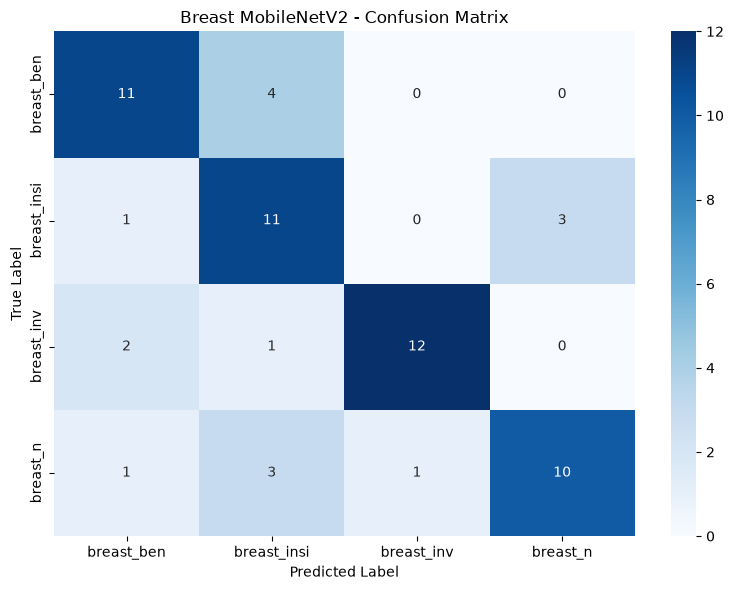

In [164]:
plt.figure(figsize=(8, 6))

sns.heatmap(
    breast_cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=breast_class_names,
    yticklabels=breast_class_names
)

plt.title("Breast MobileNetV2 - Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

plt.tight_layout()
plt.show()

Breast MobileNetV2 confusion matrix confirms that the model correctly classified 44 out of 60 test images, achieving 73.33% accuracy.

In [165]:
print(classification_report(breast_true, breast_pred, target_names=breast_class_names, digits=4))

              precision    recall  f1-score   support

  breast_ben     0.7333    0.7333    0.7333        15
 breast_insi     0.5789    0.7333    0.6471        15
  breast_inv     0.9231    0.8000    0.8571        15
    breast_n     0.7692    0.6667    0.7143        15

    accuracy                         0.7333        60
   macro avg     0.7511    0.7333    0.7380        60
weighted avg     0.7511    0.7333    0.7380        60



In [166]:
# Save the final breast tissue classification model

breast_transfer_model.save(models_path / "breast_mobilenetv2_final.keras")

print("Final breast MobileNetV2 model saved successfully!")

Final breast MobileNetV2 model saved successfully!


### Conclusion

This project demonstrated the complete workflow of a deep learning image classification system, including data preparation, duplicate removal, dataset splitting, image preprocessing, CNN development, transfer learning, model evaluation, and model saving.

The results show that deep learning can identify patterns in histopathological images, while also highlighting the challenges of limited data, model generalization, and classification errors.

**The final outcome is three independent specialist models for lung, colon, and breast tissue classification, forming the foundation for an educational multi-cancer histopathology classification application.**

*Disclaimer: This project was developed for educational and research purposes only. The models are not clinically validated and must not be used for medical diagnosis or treatment decisions.*